# 07 - Final Evaluation on the Standard Test Partition

**Three arms, one protocol**

This notebook reports the standard test partition for every arm of the study. The
partition was read once, after all configuration and checkpoint decisions had been
made, by one evaluation script, in a single precision inference pass per model.
No checkpoint was re-selected, trained again, or modified.

| Arm | Why it is here |
|---|---|
| Selected model | The proposed configuration |
| Single-image ResNet-18 baseline | The reference against which the literature comparison is made |
| Backbone-matched control | The same backbone and recipe as the selected model with stereo, text guidance, and enhancement disabled |

The control is the arm that carries the attribution argument: because it shares the
selected recipe and differs only in the three module switches, a difference between
it and the selected model cannot be attributed to the recipe or to backbone capacity.

The comparison is read against a noise band fixed before the run: a macro-F1
difference smaller than approximately 0.019 is reported as unresolved in either
direction, not as a win for whichever model has the higher point estimate.

> Run the evaluation step for all three arms before executing this notebook.

In [1]:
%matplotlib inline

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from sklearn.metrics import classification_report

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

EVAL_ROOT = ROOT / 'results' / 'experiment_1_standard'
ARMATES = {
    'selected': EVAL_ROOT,
    'baseline': EVAL_ROOT / 'baseline',
    'control': EVAL_ROOT / 'control',
}

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 220)

# Pre-specified interpretation threshold on macro F1, estimated from the
# run-to-run variability of the training procedure.
NOISE_BAND = 0.019

# Below this many test samples, a row of a normalised confusion matrix moves by
# more than seven percentage points when one image changes side, so such rows are
# excluded from the difference heat maps.
LOW_SUPPORT = 20

for name, directory in ARMATES.items():
    status = 'present' if (directory / 'metrics.json').exists() else 'MISSING'
    print(f'{name:<9} {directory.relative_to(ROOT)}  ->  {status}')

selected  results\experiment_1_standard  ->  present
baseline  results\experiment_1_standard\baseline  ->  present
control   results\experiment_1_standard\control  ->  present


## 1. Provenance and integrity

Before any number is read, the artefacts are checked against each other. The
confusion matrix must sum to the number of samples evaluated, its diagonal must
reproduce the reported accuracy, and the per-class supports must sum to the same
total. A metric that fails these checks is not reported.

The provenance block records which checkpoint produced each result, its hash, the
epoch it came from, the partition, and the numeric precision used.

In [2]:
def load_arm(directory):
    bundle = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    return {
        'label': bundle['label'],
        'class_names': bundle['class_names'],
        'metrics': bundle['metrics'],
        'provenance': bundle['provenance'],
        'cm': np.load(directory / 'confusion_matrix.npy'),
        'per_class': pd.read_csv(directory / 'per_class.csv'),
    }


arms = {name: load_arm(directory) for name, directory in ARMATES.items()}
reference_names = arms['selected']['class_names']

for name, arm in arms.items():
    cm = arm['cm']
    m = arm['metrics']
    total = int(cm.sum())
    supports = int(arm['per_class']['support'].sum())

    assert cm.shape == (17, 17), f'{name}: unexpected matrix shape {cm.shape}'
    assert total == arm['provenance']['n_samples'], f'{name}: matrix total mismatch'
    assert supports == total, f'{name}: per-class supports mismatch'
    assert len(arm['per_class']) == 17, f'{name}: not all classes present'
    assert abs(np.trace(cm) / total - m['overall_accuracy']) < 1e-12, f'{name}: accuracy'
    assert arm['class_names'] == reference_names, f'{name}: class order differs'

IDENTICAL_SPLIT = len({a['provenance']['split_sha256'] for a in arms.values()}) == 1
print(f'{len(arms)} arms pass integrity checks; identical split hash: {IDENTICAL_SPLIT}')

provenance_table = pd.DataFrame(
    [
        {
            'arm': arm['label'],
            'epoch': arm['provenance']['checkpoint_epoch'],
            'parameters': f"{arm['provenance']['parameters']:,}",
            'samples': arm['provenance']['n_samples'],
            'precision': arm['provenance']['precision'],
            'sha256': arm['provenance']['checkpoint_sha256'][:16] + '...',
        }
        for arm in arms.values()
    ]
)
provenance_table

3 arms pass integrity checks; identical split hash: True


,arm,epoch,parameters,samples,precision,sha256
0,SENSE (selected configuration),45,"33,565,001",2465,float32,6F426A2FD0ACA9A7...
1,Single-image ResNet-18 baseline,19,"11,185,233",2465,float32,121A2C9521CB46B5...
2,Backbone-matched control,44,"19,526,489",2465,float32,30C18D236B7AFD65...


## 2. Composition of the test partition

Every row of a normalised confusion matrix is divided by its own class count, so a
row with seven samples moves by 14 percentage points when a single image changes
side. The distribution is shown once here, because it applies to all three arms.

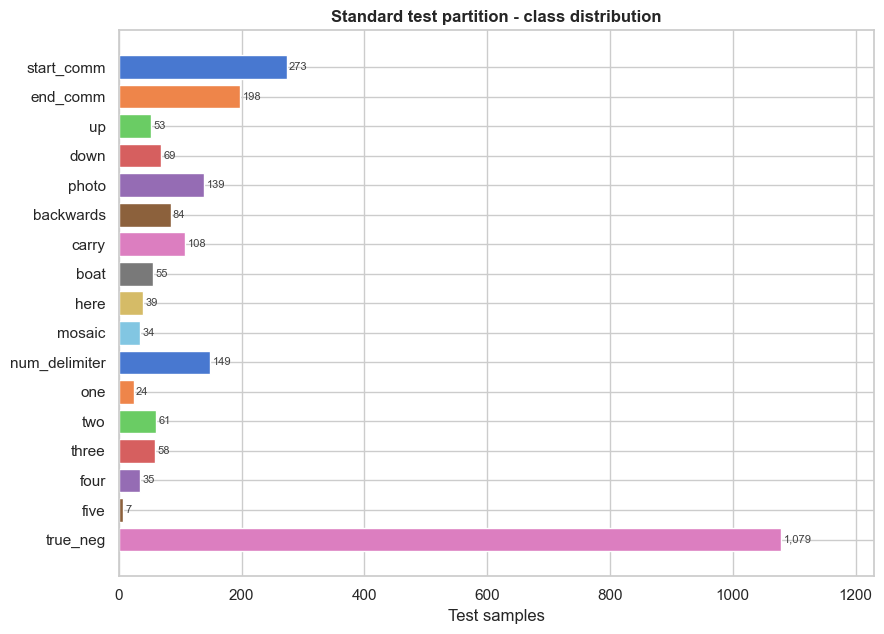

classes with fewer than 20 samples: ['five']
smallest support: 7


In [3]:
support_order = arms['selected']['per_class'].sort_values('class_id').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(support_order['class_name'], support_order['support'],
               color=sns.color_palette('muted', len(support_order)))
for bar, n in zip(bars, support_order['support']):
    ax.text(bar.get_width() + 4, bar.get_y() + bar.get_height() / 2, f'{int(n):,}',
            va='center', fontsize=8, color='0.25')
ax.invert_yaxis()
ax.set_xlim(0, support_order['support'].max() * 1.14)
ax.set_xlabel('Test samples')
ax.set_title('Standard test partition - class distribution', fontweight='bold')
plt.tight_layout()
plt.savefig(EVAL_ROOT / 'test_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

low_support_classes = support_order[support_order['support'] < LOW_SUPPORT]['class_name'].tolist()
print(f"classes with fewer than {LOW_SUPPORT} samples: {low_support_classes}")
print(f"smallest support: {int(support_order['support'].min())}")

## 3. Selected model - confusion matrix

Rows are normalised, so each row sums to one and the diagonal is the per-class
accuracy. Off-diagonal mass shows which classes are confused with which, which is
the information an aggregate metric discards.

The saved artefact is `confusion_matrix_norm.png` in the evaluation directory; the
cell redraws it from the stored counts.

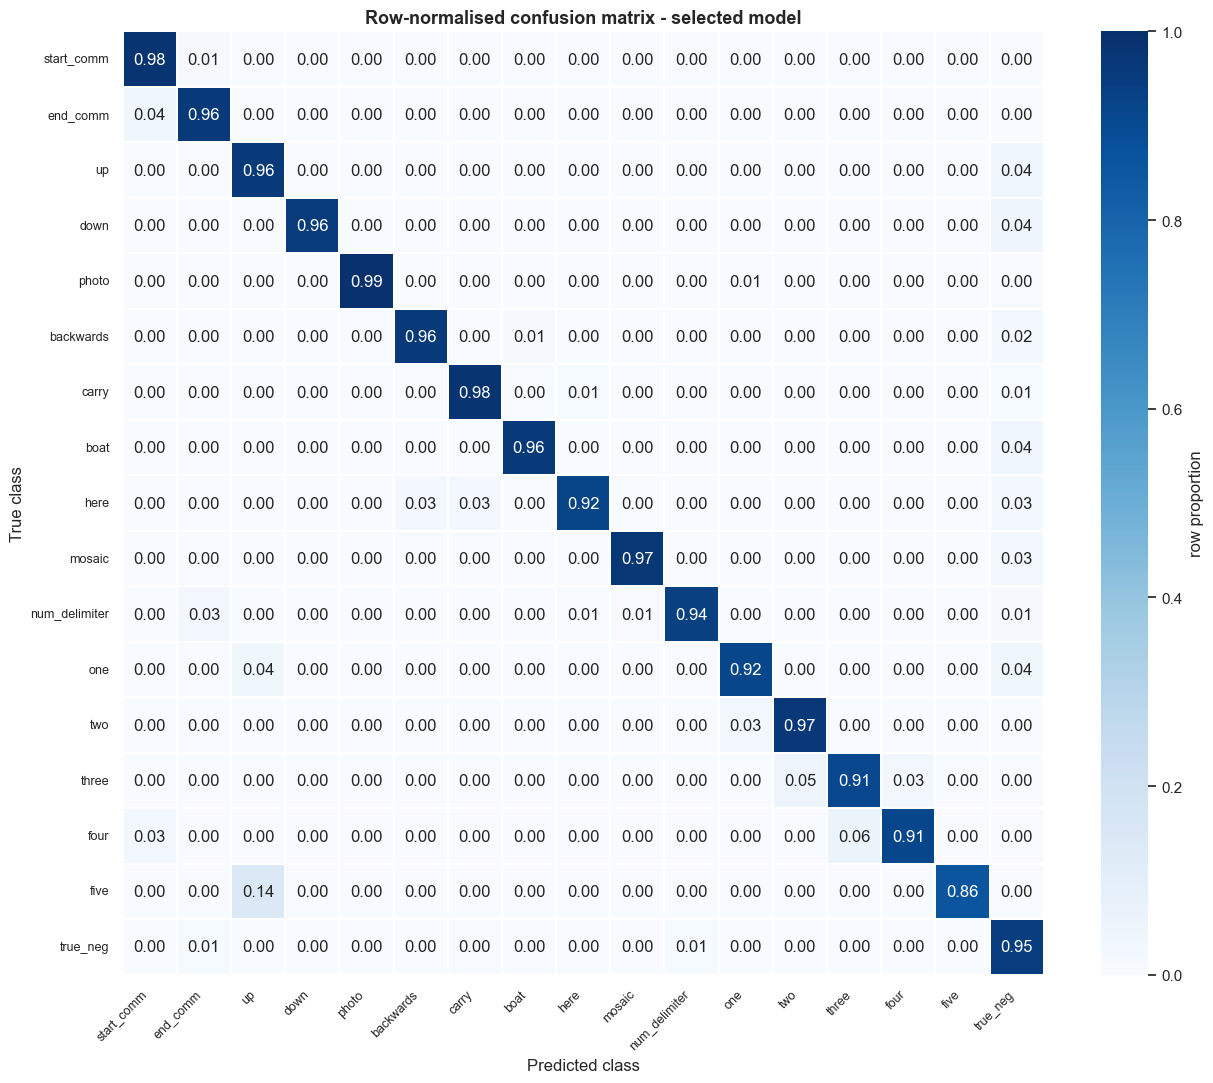

test accuracy : 0.956592
test macro F1 : 0.939838
correct       : 2,358 / 2,465


In [4]:
sense = arms['selected']
class_names = sense['class_names']
supports = sense['cm'].sum(axis=1)


def normalise(cm):
    return cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)


cm_norm = normalise(sense['cm'])

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    cm_norm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names,
    ax=ax, linewidths=0.3, vmin=0.0, vmax=1.0,
    cbar_kws={'label': 'row proportion'},
)
ax.set_title('Row-normalised confusion matrix - selected model', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

off = sense['cm'].copy()
np.fill_diagonal(off, 0)
trace = int(np.trace(sense['cm']))
print(f'test accuracy : {sense["metrics"]["overall_accuracy"]:.6f}')
print(f'test macro F1 : {sense["metrics"]["macro_f1"]:.6f}')
print(f'correct       : {trace:,} / {int(sense["cm"].sum()):,}')

## 4. Selected model - classification report

Precision, recall, and F1 per class with support. Predictions are reconstructed from
the stored confusion matrix, which is lossless for these quantities because the
matrix counts every (true, predicted) pair.

Every class is reported. The rare classes carry the same weight in macro F1 as the
frequent ones, so a reader comparing macro F1 across studies needs the support
column to know how much evidence stands behind each term.

In [5]:
def reconstruct_labels(cm):
    y_true, y_pred = [], []
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            count = int(cm[i, j])
            if count:
                y_true.extend([i] * count)
                y_pred.extend([j] * count)
    return y_true, y_pred


y_true, y_pred = reconstruct_labels(sense['cm'])
print(
    classification_report(
        y_true, y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)

               precision    recall  f1-score   support

   start_comm     0.9537    0.9817    0.9675       273
     end_comm     0.9048    0.9596    0.9314       198
           up     0.9444    0.9623    0.9533        53
         down     0.9706    0.9565    0.9635        69
        photo     0.9787    0.9928    0.9857       139
    backwards     0.9419    0.9643    0.9529        84
        carry     0.9464    0.9815    0.9636       108
         boat     0.8983    0.9636    0.9298        55
         here     0.9000    0.9231    0.9114        39
       mosaic     0.9429    0.9706    0.9565        34
num_delimiter     0.9211    0.9396    0.9302       149
          one     0.8148    0.9167    0.8627        24
          two     0.9365    0.9672    0.9516        61
        three     0.9636    0.9138    0.9381        58
         four     0.8649    0.9143    0.8889        35
         five     1.0000    0.8571    0.9231         7
     true_neg     0.9856    0.9490    0.9669      1079

     acc

In [6]:
per_class = sense['per_class'].copy()
per_class = per_class[
    ['class_id', 'class_name', 'support', 'correct', 'accuracy', 'precision', 'recall', 'f1']
]

print(f"support sums to {int(per_class['support'].sum()):,}")
print(f"correct sums to {int(per_class['correct'].sum()):,}")
per_class.round(4)

support sums to 2,465
correct sums to 2,358


,class_id,class_name,support,correct,accuracy,precision,recall,f1
0,0,start_comm,273,268,0.9817,0.9537,0.9817,0.9675
1,1,end_comm,198,190,0.9596,0.9048,0.9596,0.9314
2,2,up,53,51,0.9623,0.9444,0.9623,0.9533
3,3,down,69,66,0.9565,0.9706,0.9565,0.9635
4,4,photo,139,138,0.9928,0.9787,0.9928,0.9857
5,5,backwards,84,81,0.9643,0.9419,0.9643,0.9529
6,6,carry,108,106,0.9815,0.9464,0.9815,0.9636
7,7,boat,55,53,0.9636,0.8983,0.9636,0.9298
8,8,here,39,36,0.9231,0.9000,0.9231,0.9114
9,9,mosaic,34,33,0.9706,0.9429,0.9706,0.9565


## 5. Selected model - per-class F1 and the three per-class metrics

F1 by class, with the support printed above each bar and the macro F1 marked. The
gap between a bar and the reference line is not a measure of how much a class could
be improved; a short bar on a small class may simply be a short bar on little
evidence.

The heat map on the right of the second cell shows the same numbers alongside
precision and recall, on a truncated colour scale, because every value sits in a
narrow band and a full-range scale would render the table a single colour.

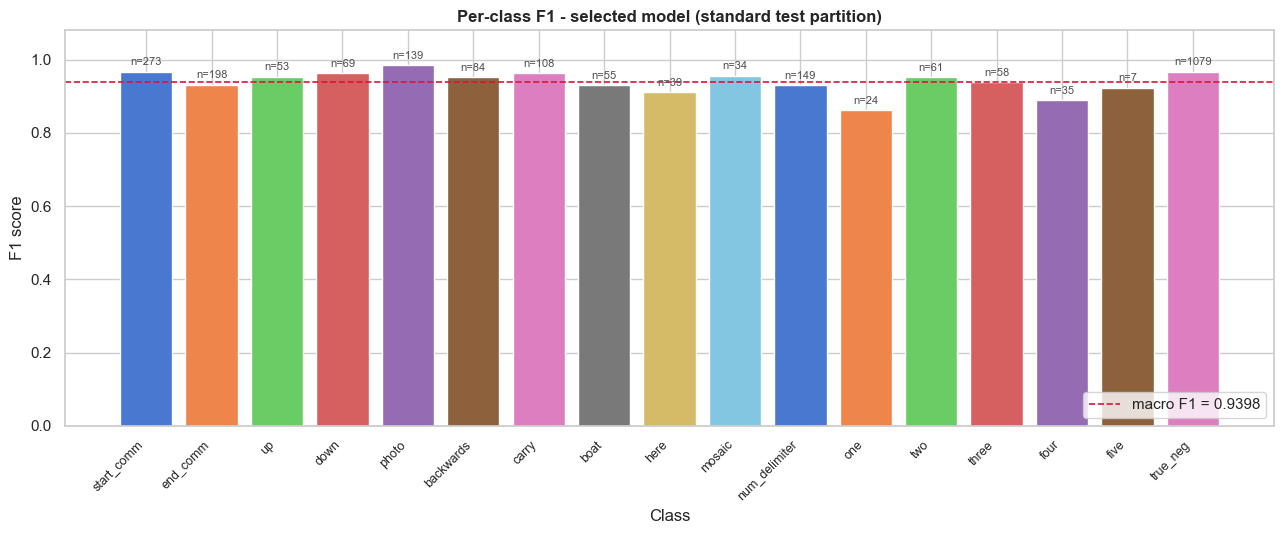

lowest F1       : one (0.8627, n=24)
lowest accuracy : five (0.8571, n=7)


In [7]:
order = per_class.sort_values('class_id').reset_index(drop=True)
colors = sns.color_palette('muted', n_colors=len(order))

fig, ax = plt.subplots(figsize=(13, 5.5))
bars = ax.bar(order['class_name'], order['f1'], color=colors)
for bar, support in zip(bars, order['support']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.012,
            f'n={int(support)}', ha='center', va='bottom', fontsize=8, color='0.3')
ax.set_ylim(0, 1.08)
ax.set_ylabel('F1 score')
ax.set_xlabel('Class')
ax.set_title('Per-class F1 - selected model (standard test partition)', fontweight='bold')
ax.axhline(sense['metrics']['macro_f1'], color='crimson', linestyle='--', linewidth=1.2,
           label=f"macro F1 = {sense['metrics']['macro_f1']:.4f}")
plt.xticks(rotation=45, ha='right', fontsize=9)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(EVAL_ROOT / 'per_class_f1.png', dpi=150, bbox_inches='tight')
plt.show()

worst = order.loc[order['f1'].idxmin()]
binding = order.loc[order['accuracy'].idxmin()]
print(f"lowest F1       : {worst['class_name']} ({worst['f1']:.4f}, n={int(worst['support'])})")
print(f"lowest accuracy : {binding['class_name']} ({binding['accuracy']:.4f}, n={int(binding['support'])})")

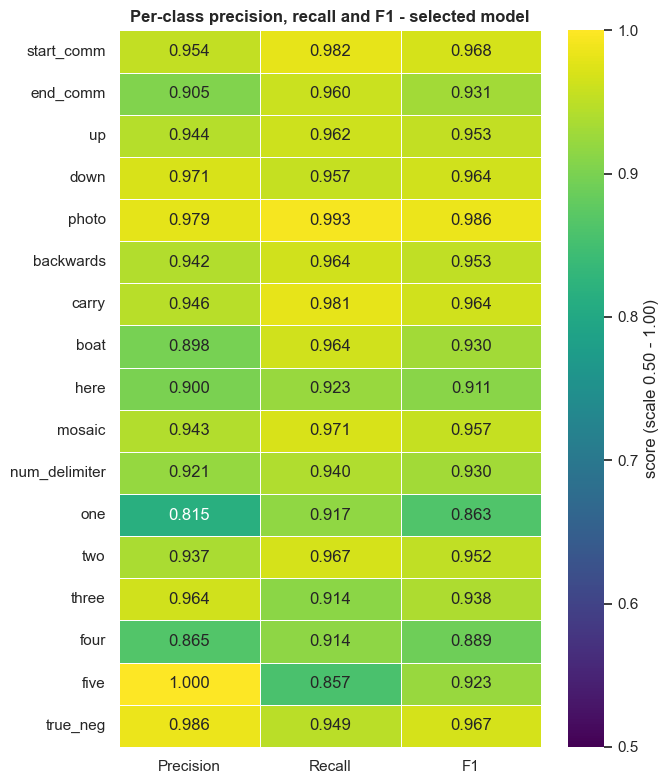

colour scale starts at 0.50; lowest value in the table is 0.8148


In [8]:
metric_cols = ['precision', 'recall', 'f1']
prf = order[metric_cols].to_numpy(dtype=float)
vmin = min(0.5, float(np.floor(prf.min() * 20) / 20))

fig, ax = plt.subplots(figsize=(6.8, 8))
sns.heatmap(
    prf, annot=True, fmt='.3f', cmap='viridis', vmin=vmin, vmax=1.0,
    xticklabels=['Precision', 'Recall', 'F1'], yticklabels=order['class_name'],
    ax=ax, linewidths=0.4, cbar_kws={'label': f'score (scale {vmin:.2f} - 1.00)'},
)
ax.set_title('Per-class precision, recall and F1 - selected model', fontsize=12, fontweight='bold')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig(EVAL_ROOT / 'per_class_prf_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'colour scale starts at {vmin:.2f}; lowest value in the table is {prf.min():.4f}')

## 6. Confusion matrices for all three arms, and the differences between them

The three matrices share class order and colour scale, so a row can be compared
across arms without re-reading the axes.

The difference panels show the selected model minus the other arm, in percentage
points of the row. Blue means the selected model recovers images that the other arm
loses; red means the reverse. Rows with fewer than twenty test samples are excluded,
because in such a row one image is worth more than five percentage points and the
colour would reflect the sample size rather than the model.

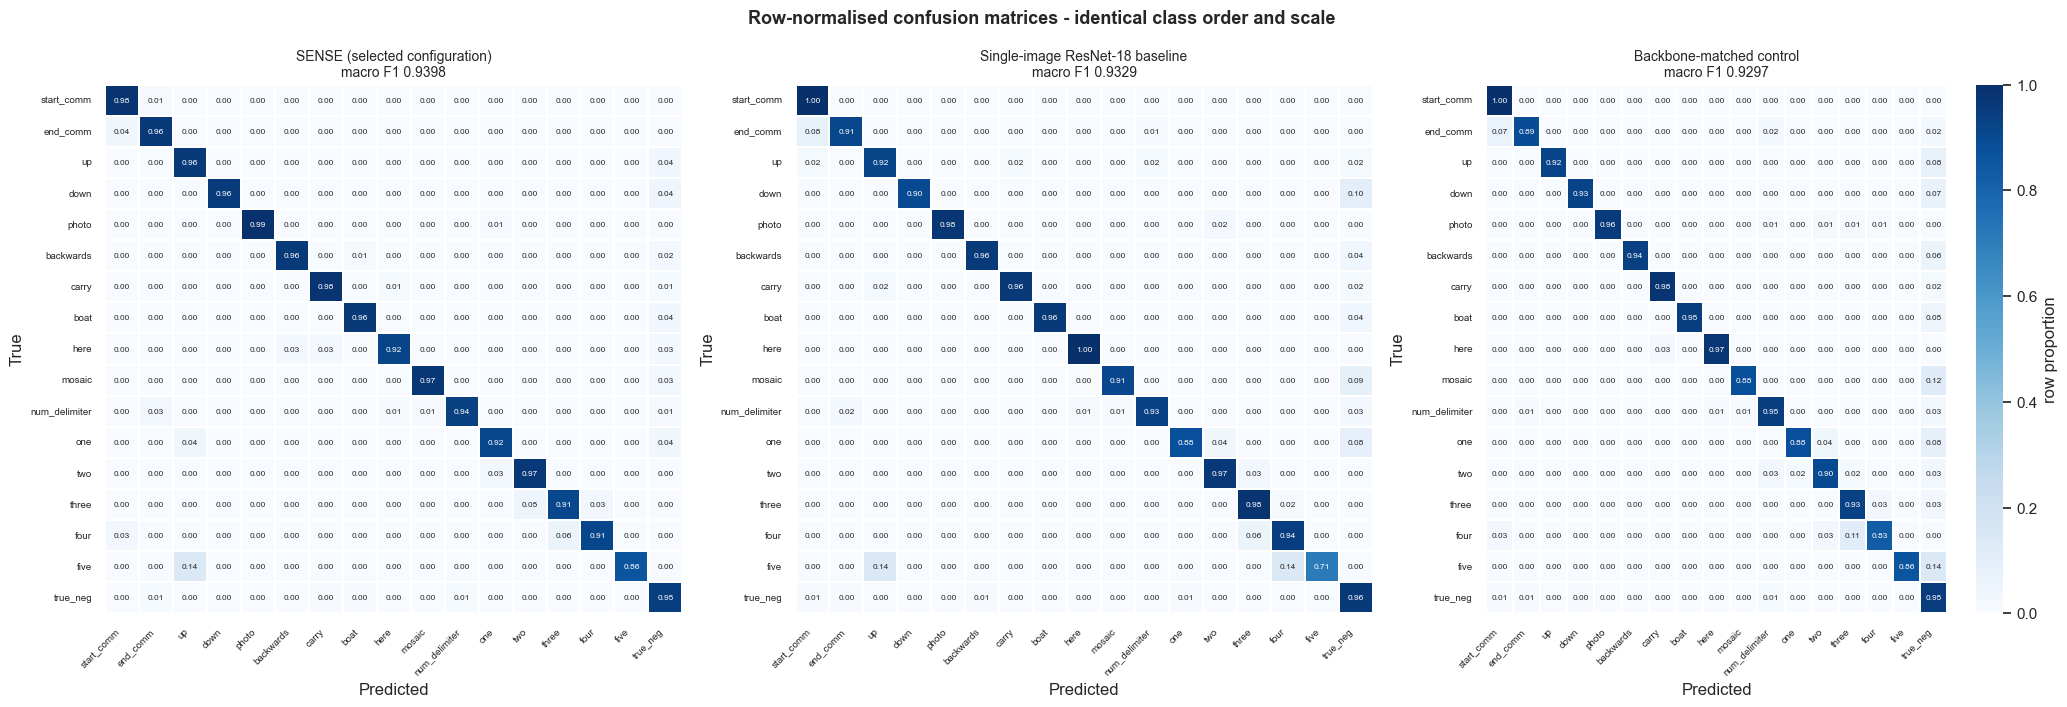

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7.2))
for ax, (name, arm) in zip(axes, arms.items()):
    sns.heatmap(
        normalise(arm['cm']), annot=True, fmt='.2f', cmap='Blues',
        xticklabels=class_names, yticklabels=class_names,
        vmin=0.0, vmax=1.0, ax=ax, linewidths=0.25,
        annot_kws={'fontsize': 6},
        cbar=(name == 'control'),
        cbar_kws={'label': 'row proportion'},
    )
    ax.set_title(f"{arm['label']}\nmacro F1 {arm['metrics']['macro_f1']:.4f}", fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(labelsize=7)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
fig.suptitle('Row-normalised confusion matrices - identical class order and scale',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(EVAL_ROOT / 'confusion_matrices_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

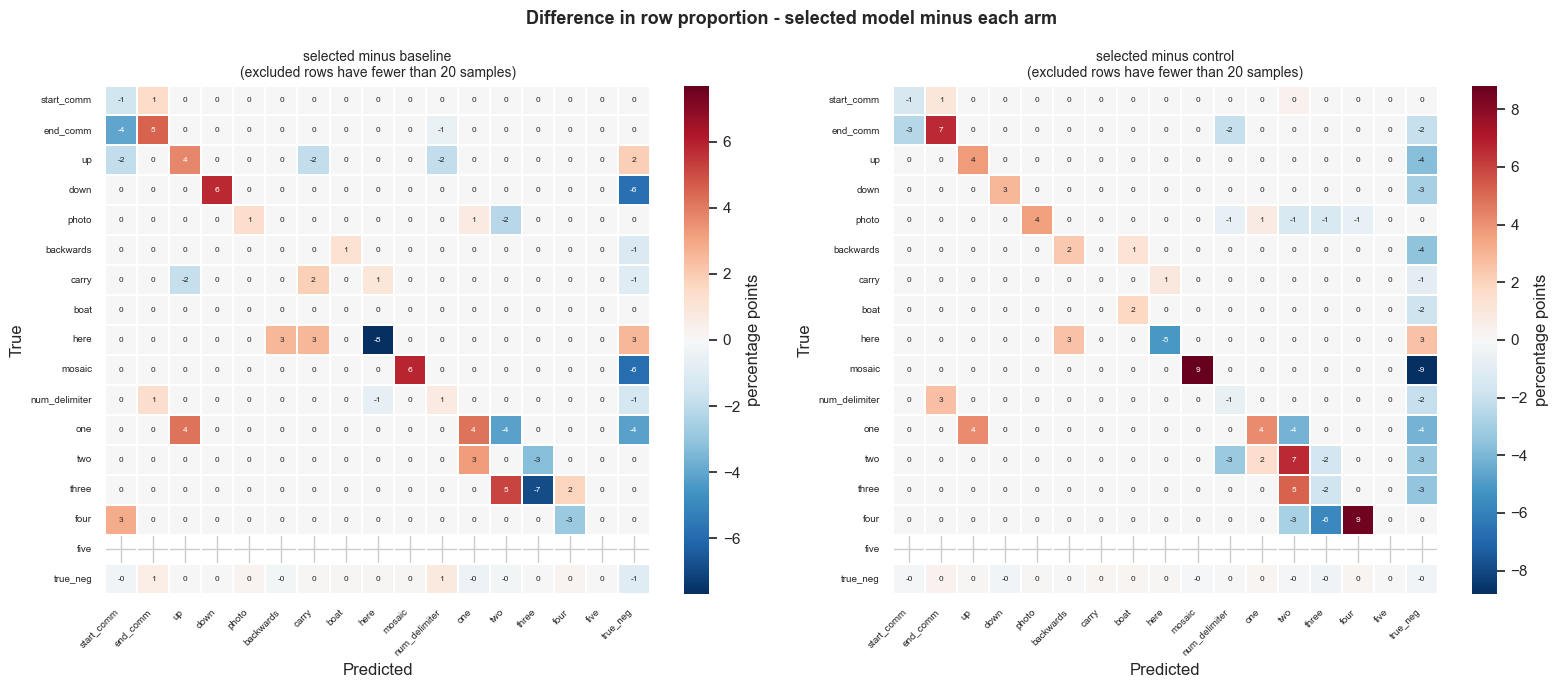

excluded rows (1): ['five']


In [10]:
comparisons = [('baseline', 'baseline'), ('control', 'control')]
low_rows = supports < LOW_SUPPORT

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (key, label) in zip(axes, comparisons):
    diff_pp = (cm_norm - normalise(arms[key]['cm'])) * 100.0
    diff_pp = np.where(low_rows[:, None], np.nan, diff_pp)
    limit = np.nanmax(np.abs(diff_pp))
    sns.heatmap(
        diff_pp, annot=True, fmt='.0f', cmap='RdBu_r',
        norm=TwoSlopeNorm(vcenter=0.0, vmin=-limit, vmax=limit),
        xticklabels=class_names, yticklabels=class_names,
        ax=ax, linewidths=0.25, annot_kws={'fontsize': 6},
        cbar_kws={'label': 'percentage points'}, mask=np.isnan(diff_pp),
    )
    ax.set_title(f"selected minus {label}\n(excluded rows have fewer than {LOW_SUPPORT} samples)",
                 fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(labelsize=7)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
fig.suptitle('Difference in row proportion - selected model minus each arm',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(EVAL_ROOT / 'confusion_differences.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'excluded rows ({int(low_rows.sum())}): '
      f'{[class_names[i] for i in np.where(low_rows)[0]]}')

## 7. Headline comparison

The three arms on the same partition, measured by the same code. The difference
columns are the selected model minus the other arm, so a positive value favours the
selected model.

The noise band was estimated from the run-to-run variability of macro F1, so it is
applied to macro F1 and shown for that row only. The other metrics are reported as
point differences with the sample sizes that qualify them, not as verdicts.

In [11]:
def headline(arm):
    m = arm['metrics']
    return {
        'Accuracy': m['overall_accuracy'],
        'Macro F1': m['macro_f1'],
        'Minimum class accuracy': m['min_class_accuracy'],
    }


scores = {name: headline(arm) for name, arm in arms.items()}
comparison = pd.DataFrame({'Metric': list(scores['selected'])})
for name in arms:
    comparison[arms[name]['label']] = list(scores[name].values())

sense_col = arms['selected']['label']
for name in ('baseline', 'control'):
    other = arms[name]['label']
    comparison[f'diff vs {name}'] = comparison[sense_col] - comparison[other]
    comparison[f'within macro-F1 band vs {name}'] = [
        ('yes' if abs(delta) < NOISE_BAND else 'no') if metric == 'Macro F1' else 'not applicable'
        for metric, delta in zip(comparison['Metric'], comparison[f'diff vs {name}'])
    ]

display(comparison.round(6))
comparison.round(6).to_csv(EVAL_ROOT / 'comparison_table.csv', index=False)
print('saved', (EVAL_ROOT / 'comparison_table.csv').relative_to(ROOT))

,Metric,SENSE (selected configuration),Single-image ResNet-18 baseline,Backbone-matched control,diff vs baseline,within macro-F1 band vs baseline,diff vs control,within macro-F1 band vs control
0,Accuracy,0.956592,0.955781,0.946450,0.000811,not applicable,0.010142,not applicable
1,Macro F1,0.939838,0.932913,0.929668,0.006925,yes,0.010170,yes
2,Minimum class accuracy,0.857143,0.714286,0.828571,0.142857,not applicable,0.028571,not applicable


saved results\experiment_1_standard\comparison_table.csv


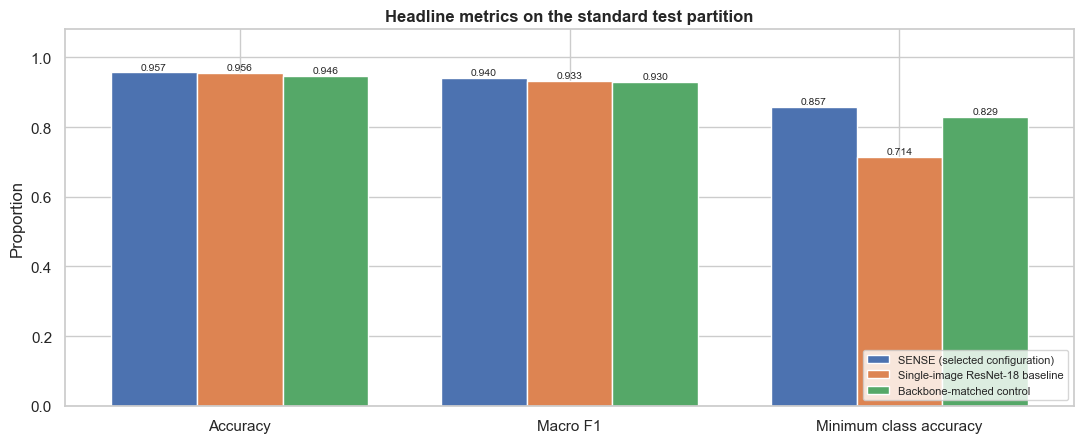

Accuracy                   vs baseline  +0.0008
Accuracy                   vs control   +0.0101
Macro F1                   vs baseline  +0.0069  (inside band)
Macro F1                   vs control   +0.0102  (inside band)
Minimum class accuracy     vs baseline  +0.1429
Minimum class accuracy     vs control   +0.0286


In [12]:
fig, ax = plt.subplots(figsize=(11, 4.6))
metrics_list = comparison['Metric'].tolist()
x = np.arange(len(metrics_list))
width = 0.26
colours = {'selected': '#4c72b0', 'baseline': '#dd8452', 'control': '#55a868'}

for offset, name in zip((-width, 0.0, width), arms):
    values = [scores[name][m] for m in metrics_list]
    bars = ax.bar(x + offset, values, width, label=arms[name]['label'], color=colours[name])
    for xi, v in zip(x + offset, values):
        ax.text(xi, v + 0.008, f'{v:.3f}', ha='center', fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels(metrics_list)
ax.set_ylim(0, 1.08)
ax.set_ylabel('Proportion')
ax.set_title('Headline metrics on the standard test partition', fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(EVAL_ROOT / 'headline_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

for metric in metrics_list:
    row = comparison.loc[comparison['Metric'] == metric].iloc[0]
    for name in ('baseline', 'control'):
        line = f'{metric:<26} vs {name:<9} {row[f"diff vs {name}"]:+.4f}'
        if metric == 'Macro F1':
            state = row[f'within macro-F1 band vs {name}']
            line += '  (inside band)' if state == 'yes' else '  (outside band)'
        print(line)

## 8. Per-class differences

Per-class F1 for the selected model minus per-class F1 for each other arm, ordered by
class index. Positive values favour the selected model.

An aggregate difference can hide a split: a model can be better on some classes and
worse on others by amounts larger than the aggregate. The per-class differences are
not tested, and with seven samples in the smallest class a single prediction moves a
per-class F1 substantially, so the charts describe where the arms disagree rather than
rank them.

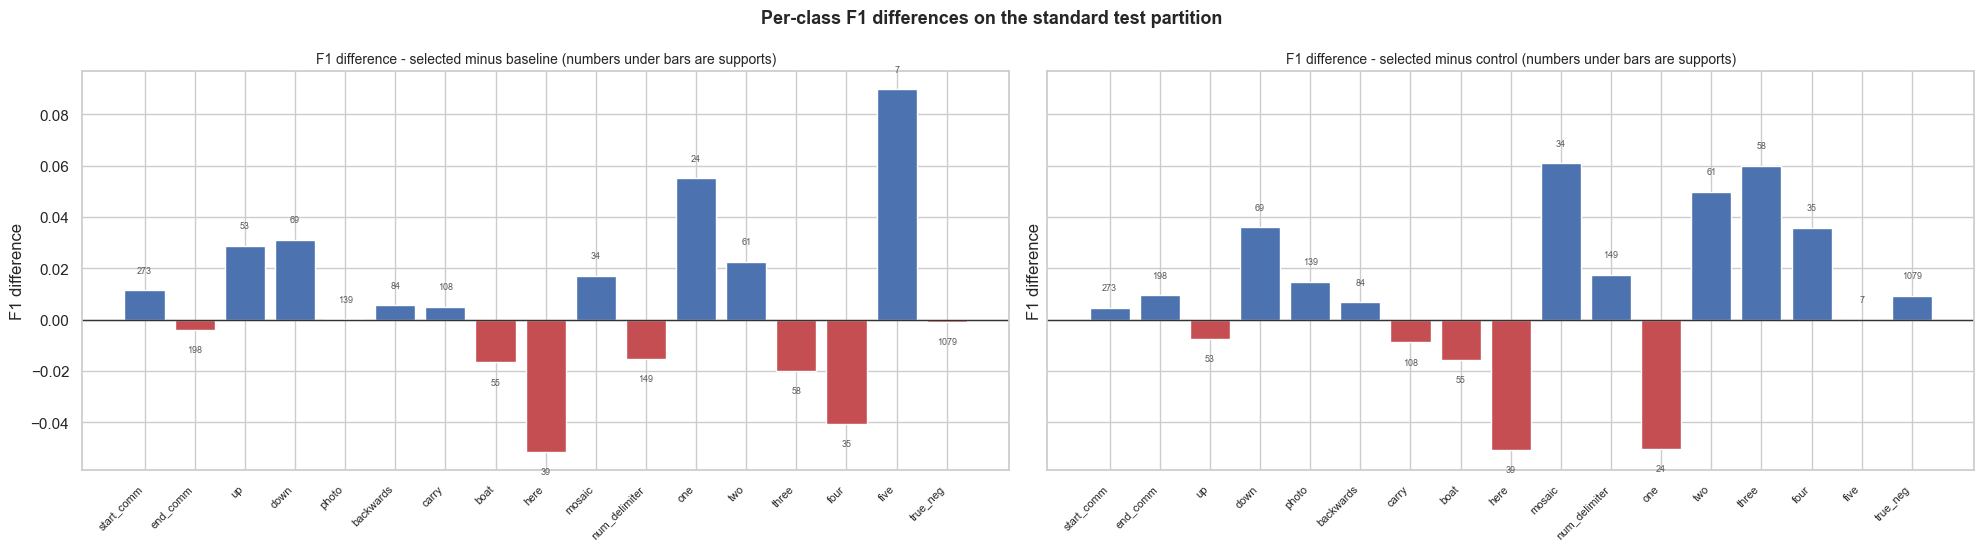

vs baseline : 10 classes favour the selected model, 7 favour baseline
vs control  : 11 classes favour the selected model, 5 favour control


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(20, 5.6), sharey=True)
tallies = {}

for ax, (key, label) in zip(axes, comparisons):
    other = arms[key]['per_class'].copy()
    merged = per_class[['class_id', 'class_name', 'support', 'f1']].merge(
        other[['class_id', 'f1']], on='class_id', suffixes=('_selected', '_other')
    )
    merged['gap'] = merged['f1_selected'] - merged['f1_other']
    merged = merged.sort_values('class_id')

    colours = ['#4c72b0' if g >= 0 else '#c44e52' for g in merged['gap']]
    bars = ax.bar(merged['class_name'], merged['gap'], color=colours)
    for bar, n in zip(bars, merged['support']):
        offset = 0.006 if bar.get_height() >= 0 else -0.006
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + offset, f'{int(n)}',
                ha='center', va='bottom' if offset > 0 else 'top', fontsize=6.5, color='0.35')
    ax.axhline(0, color='0.2', linewidth=1)
    ax.set_title(f'F1 difference - selected minus {label} (numbers under bars are supports)',
                 fontsize=10)
    ax.set_ylabel('F1 difference')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)

    tallies[key] = (int((merged['gap'] > 0).sum()), int((merged['gap'] < 0).sum()))

fig.suptitle('Per-class F1 differences on the standard test partition',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(EVAL_ROOT / 'per_class_gap.png', dpi=150, bbox_inches='tight')
plt.show()

for key, (pos, neg) in tallies.items():
    print(f'vs {key:<9}: {pos} classes favour the selected model, {neg} favour {key}')

## 9. Reading rule and summary

The rule applied to this comparison was fixed before the run, and it is repeated here
so that the summary cannot be read as a post-hoc choice:

1. A macro-F1 difference smaller than the noise band is unresolved, in either direction.
2. Per-class results are reported in full, for every class, whatever the aggregate says.
3. A reversal of the validation ordering is recorded as a finding.
4. A minimum-class difference is qualified by the support of the class that attains it.
5. The three arms were fixed before the partition was read; no arm was added after
   seeing a result, and no model was selected on the test partition.

In [14]:
lines = []
for name in ('selected', 'baseline', 'control'):
    m = arms[name]['metrics']
    lines.append(
        f"{arms[name]['label']}: accuracy {m['overall_accuracy']:.6f}, "
        f"macro F1 {m['macro_f1']:.6f}, minimum class accuracy {m['min_class_accuracy']:.6f}."
    )
lines.append('')

for name in ('baseline', 'control'):
    row = comparison.loc[comparison['Metric'] == 'Macro F1'].iloc[0]
    delta = row[f'diff vs {name}']
    state = 'inside' if abs(delta) < NOISE_BAND else 'outside'
    lines.append(f'Macro F1 difference vs {name}: {delta:+.4f} against a noise band of {NOISE_BAND:.3f} ({state}).')

origin = comparison.loc[comparison['Metric'] == 'Minimum class accuracy'].iloc[0]
for name in ('baseline', 'control'):
    arm = arms[name]
    cls = arm['per_class'].loc[arm['per_class']['accuracy'].idxmin()]
    lines.append(
        f"The minimum for {name} is attained on '{cls['class_name']}' with n={int(cls['support'])}; "
        f"the difference on that metric is {origin[f'diff vs {name}']:+.4f}."
    )

print('\n'.join(lines))

print()
unresolved = [
    name for name in ('baseline', 'control')
    if abs(comparison.loc[comparison['Metric'] == 'Macro F1'].iloc[0][f'diff vs {name}']) < NOISE_BAND
    ]
if unresolved:
    joined = ' and the '.join(unresolved)
    noun, verb = ('difference', 'lies') if len(unresolved) == 1 else ('differences', 'lie')
    print(f'VERDICT: the macro-F1 {noun} against the {joined} {verb} inside the noise band.')
    print('         Those comparisons are UNRESOLVED. No superiority claim is made.')
resolved = [name for name in ('baseline', 'control') if name not in unresolved]
if resolved:
    joined = ' and the '.join(resolved)
    noun, verb = ('difference', 'lies') if len(resolved) == 1 else ('differences', 'lie')
    print(f'VERDICT: the macro-F1 {noun} against the {joined} {verb} outside the noise band.')
    print('         The direction is reported, subject to the single-seed limitation.')

SENSE (selected configuration): accuracy 0.956592, macro F1 0.939838, minimum class accuracy 0.857143.
Single-image ResNet-18 baseline: accuracy 0.955781, macro F1 0.932913, minimum class accuracy 0.714286.
Backbone-matched control: accuracy 0.946450, macro F1 0.929668, minimum class accuracy 0.828571.

Macro F1 difference vs baseline: +0.0069 against a noise band of 0.019 (inside).
Macro F1 difference vs control: +0.0102 against a noise band of 0.019 (inside).
The minimum for baseline is attained on 'five' with n=7; the difference on that metric is +0.1429.
The minimum for control is attained on 'four' with n=35; the difference on that metric is +0.0286.

VERDICT: the macro-F1 differences against the baseline and the control lie inside the noise band.
         Those comparisons are UNRESOLVED. No superiority claim is made.


---

**What this notebook does not do**

- It does not select a model. All three checkpoints were frozen before the partition was read.
- It does not test significance. The noise band is a threshold for interpretation, not a
  confidence interval, and no p-value is computed here.
- It does not report cross-scenario behaviour. No leave-one-scenario-out evaluation has
  been run, so no robustness claim is available from this partition.
- It does not attribute the difference to a single component. The control isolates the
  three modules jointly; separating stereo from text guidance from enhancement requires
  the ablation arms, which have not been trained.
- It does not report latency. Inference speed was excluded from the study by decision, so
  no efficiency claim is made.

**Artefacts written by this notebook**

| File | Content |
|---|---|
| `test_class_distribution.png` | Composition of the test partition by class |
| `per_class_f1.png` | Per-class F1 for the selected model, support annotated |
| `per_class_prf_heatmap.png` | Precision, recall, and F1 per class for the selected model |
| `confusion_matrices_comparison.png` | The three arms on one figure, identical scale |
| `confusion_differences.png` | Selected minus baseline, and selected minus control |
| `headline_comparison.png` | Headline metrics for all three arms |
| `per_class_gap.png` | Per-class F1 differences for both comparisons |
| `comparison_table.csv` | The comparison table in machine-readable form |